# Notebook 5 — Dynamic aperture

Load one of the rings saved by notebooks 3 and 4 and study particle survival, following the [Xsuite dynamic-aperture example](https://xsuite.readthedocs.io/en/latest/dynamic_aperture.html).

## Your tasks

1. Load `ring_dba.json` or `ring_fodo.json` and inspect its tunes and chromaticities.
2. Install a circular aperture of **10 cm radius** at each cell entrance to remove particles whose amplitudes grow large.
3. Calculate the horizontal equilibrium emittance from radiation integrals. Use it to normalize the horizontal amplitudes and assume a vertical emittance equal to 1% of it. Generate a polar grid with zero initial normalized momenta and `delta = 0`.
4. Track for **200 turns** and plot the number of completed turns against the initial amplitudes.
5. Repeat for the other lattice with the same settings. Increase the amplitude range if the scan does not reach losses; increase the number of turns to check how the survival boundary changes.

This is a first-quadrant, fixed-momentum survival scan with the added physical aperture. With no RF or radiation, the momentum deviation remains fixed during tracking. The result samples one choice of initial betatron phases over a finite number of turns.

### Load a matched ring

In [62]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt
import xpart as xp

In [63]:
# lattice_file = 'ring_dba.json'  # Or 'ring_fodo.json'
lattice_file = 'ring_fodo.json'  # Or 'ring_fodo.json'
line = xt.load(lattice_file)

tw = line.twiss4d()
print(f'Tunes: {tw.qx:.4f} / {tw.qy:.4f}')
print(f'Chromaticities: {tw.dqx:.4f} / {tw.dqy:.4f}')

Loading line from dict:   0%|          | 0/106 [00:00<?, ?it/s]

Done loading line from dict.           
Tunes: 4.0444 / 4.0889
Chromaticities: 0.5000 / 0.5000


### Equilibrium emittance and amplitude scales

Calculate radiation integrals on a sliced copy of the loaded ring. Use the horizontal equilibrium geometric emittance for the horizontal launch scale.

The ideal uncoupled lattice has zero vertical equilibrium emittance. For a finite vertical beam-size scale, **assume $\epsilon_y = 0.01\epsilon_x$**. This assumption only sets the launch amplitudes; it does not introduce coupling or vertical dispersion into the tracked ring. Radiation remains off during the dynamic-aperture tracking.

In [64]:
line_rad = line.copy()
line_rad.slice_thick_elements(slicing_strategies=[
    xt.Strategy(slicing=None),
    xt.Strategy(slicing=xt.Uniform(100, mode='thick'), element_type=xt.Bend),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
])
tw_rad = line_rad.twiss4d(radiation_integrals=True)

gemitt_x = tw_rad.rad_int_eq_gemitt_x
gemitt_y = gemitt_x
print(f'Horizontal equilibrium emittance: {gemitt_x * 1e9:.3f} nm rad')
print(f'Assumed vertical emittance (1%): {gemitt_y * 1e9:.3f} nm rad')

Slicing line:   0%|          | 0/192 [00:00<?, ?it/s]

Horizontal equilibrium emittance: 160.364 nm rad
Assumed vertical emittance (1%): 160.364 nm rad


### Install the aperture

Use the same generous aperture in both rings. It is checked at each cell entrance, rather than continuously along the magnets.

In [65]:
aperture_radius = 0.10  # [m]
line.env.new('aperture_da', xt.LimitEllipse,
             a=aperture_radius, b=aperture_radius)
line.insert([
    line.env.place('aperture_da', at=s)
    for s in np.arange(0, line.get_length(), line['l_cell'])
])

Slicing line:   0%|          | 0/192 [00:00<?, ?it/s]

### Generate the launch grid

Amplitudes are in beam-size units using the horizontal equilibrium emittance and the assumed vertical emittance above. Use the same settings for both rings; their physical launch amplitudes will differ because their emittances and beta functions differ.

In [66]:
n_r = 30
n_theta = 25
r_max = 200  # Beam sigmas
num_turns = 200
delta_init = 0

x_normalized, y_normalized, r_xy, theta_xy = xp.generate_2D_polar_grid(
    r_range=(0, r_max),
    theta_range=(0, np.pi / 2),
    nr=n_r, ntheta=n_theta,
)

In [67]:
particles = line.build_particles(
    method='4d',
    x_norm=x_normalized, px_norm=0,
    y_norm=y_normalized, py_norm=0,
    gemitt_x=gemitt_x, gemitt_y=gemitt_y,
    delta=delta_init,
)

### Track the particles

In [68]:
line.track(particles, num_turns=num_turns,
           time=True, with_progress=5)
print(f'Tracked in {line.time_last_track:.2f} seconds')

Tracking:   0%|          | 0/200 [00:00<?, ?it/s]

Tracked in 11.08 seconds


### Restore the launch order and inspect survival

Tracking moves lost particles within the particle array. Sort by particle ID before associating the results with the initial grid. Surviving particles are shown at the maximum colour value.

In [69]:
particles.sort(interleave_lost_particles=True)
survived = particles.state > 0
turns_survived = np.where(survived, num_turns, particles.at_turn)
print(f'{np.count_nonzero(survived)} / {len(survived)} particles survived {num_turns} turns')

268 / 750 particles survived 200 turns


### Scatter plot

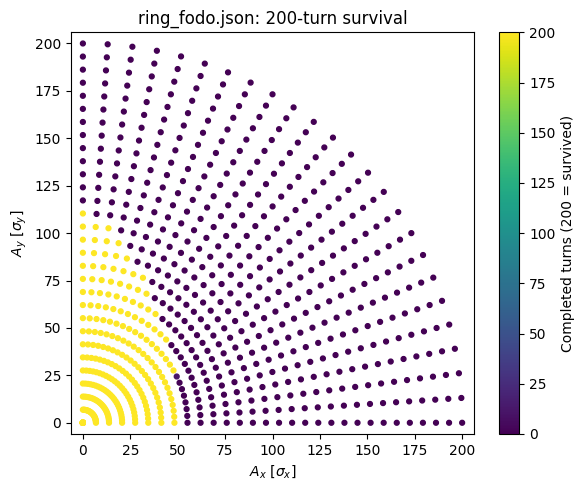

In [70]:
plt.figure(figsize=(6, 5))
plt.scatter(x_normalized, y_normalized, c=turns_survived,
            s=12, vmin=0, vmax=num_turns)
plt.xlabel(r'$A_x$ [$\sigma_x$]')
plt.ylabel(r'$A_y$ [$\sigma_y$]')
plt.colorbar(label=f'Completed turns ({num_turns} = survived)')
plt.title(f'{lattice_file}: {num_turns}-turn survival')
plt.axis('equal')
plt.tight_layout()

### Colour map

This is the same scan displayed on the polar mesh. The interpolation is for display; the scatter plot shows the actual sampled launches.

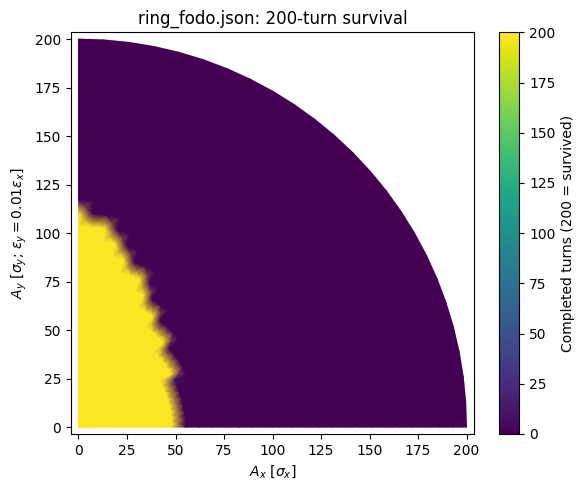

In [71]:
plt.figure(figsize=(6, 5))
plt.pcolormesh(
    x_normalized.reshape(n_r, n_theta),
    y_normalized.reshape(n_r, n_theta),
    turns_survived.reshape(n_r, n_theta),
    shading='gouraud', vmin=0, vmax=num_turns,
)
plt.xlabel(r'$A_x$ [$\sigma_x$]')
plt.ylabel(r'$A_y$ [$\sigma_y$; $\epsilon_y=0.01\epsilon_x$]')
plt.colorbar(label=f'Completed turns ({num_turns} = survived)')
plt.title(f'{lattice_file}: {num_turns}-turn survival')
plt.axis('equal')
plt.tight_layout()